# Zilionis 2019 NSCLC — 04 · EMT-TF expression

The expression step is **unconditional** — the final notebook regardless of gate outcomes. From a panel spanning Snail/Zeb/Twist **and** the FOXC/PRRX mesenchymal families (VIM is a marker, not a TF, and is excluded), we keep factors with detectable expression, derive the early(root)/late(terminus) pair by pseudotime trend, and overlay thresholded expressers on the grey manifold (categorical, not a continuous single-gene colormap).

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
ds   = name.split('-')[0] if '-' in name else name
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)


In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 3920 | pseudotime range 0.0 -> 9.24


### Detection-gated EMT-TF panel; derive the early/late pair

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho, p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\ndetectable TFs (frac>0.03): {ok.TF.tolist()}')
print(f'derived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 SNAI2      0.051       0.034      0.013    -0.080    EARLY(root)
  ZEB2      0.039       0.029      0.018    -0.037    EARLY(root)
  ZEB1      0.015       0.011      0.004    -0.031    EARLY(root)
 FOXC1      0.068       0.033      0.030     0.004    EARLY(root)
TWIST1      0.002       0.000      0.001     0.005 LATE(terminus)
 PRRX2      0.047       0.019      0.023     0.005 LATE(terminus)
 FOXC2      0.002       0.000      0.001     0.016 LATE(terminus)
 PRRX1      0.016       0.009      0.013     0.020 LATE(terminus)
 SNAI1      0.030       0.010      0.023     0.046 LATE(terminus)
TWIST2      0.017       0.002      0.027     0.135 LATE(terminus)

detectable TFs (frac>0.03): ['SNAI2', 'ZEB2', 'FOXC1', 'PRRX2']
derived pair: SNAI2 (early/root) <-> PRRX2 (late/terminus)


### Deliverable — `expression.pdf` (thresholded expressers on grey manifold)

overlay thresholds (upper quartile among expressers): {'SNAI2': 0.731, 'PRRX2': 0.651} | cells shown: {'SNAI2': 50, 'PRRX2': 46}
SNAI2: 5.1% expressing; 50 shown (upper quartile), mean pseudotime of shown cells = 0.39 (all = 0.47)
PRRX2: 4.7% expressing; 46 shown (upper quartile), mean pseudotime of shown cells = 0.51 (all = 0.47)
saved expression.pdf


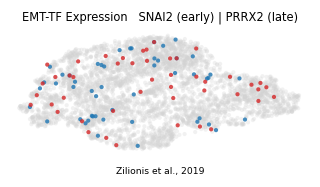

In [5]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) | {late_tf} (late)', size=7.5)
ax.text(.5, -.14, 'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')